# BRD4 QSAR — Y-randomization for the three tuned regression models

This notebook runs **one model per execution cell**:

1. ExtraTreesRegressor
2. CatBoostRegressor
3. SVR

**Observed metrics come from Stage 07.** The observed-label pooled out-of-fold (OOF) RMSE, R² and MAE are read from `outputs/07_optuna_tuning/tables/optuna_best_params.json`, i.e. the best-trial values saved by Optuna. They are not recomputed, so they match the Stage 07 tables exactly.

**Shuffled-target runs use the exact Stage 07 folds.** The five scaffold-grouped folds are loaded from the Stage 07 cache (`prepared_folds_<run_id>.joblib`); no new CV seed is drawn. Estimators, parameters, the fixed ordered 250-feature matrix and the per-fold seed rule (`seed + fold`) are the Stage 07 ones. The locked test set is not loaded or used.

**Execution order:** run the setup cells first, then ExtraTrees, CatBoost and SVR sequentially.

**Progress and recovery:** each completed permutation is checkpointed. If the kernel stops, rerun the same model cell; completed permutations are reused. The default here is **20 permutations per model**, so the smallest possible add-one empirical p-value is 1/21 ≈ 0.0476.

## 1. Locate the BRD4 project and import the runner from src/

In [1]:
from pathlib import Path
import sys
import importlib
import pandas as pd
from IPython.display import display

# Find the BRD4 project root (the directory containing outputs/ and src/).
PROJECT_ROOT = Path.cwd().resolve()
while (
    not ((PROJECT_ROOT / "outputs").is_dir() and (PROJECT_ROOT / "src").is_dir())
    and PROJECT_ROOT != PROJECT_ROOT.parent
):
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "outputs").is_dir():
    raise FileNotFoundError(f"Could not find outputs/ under {PROJECT_ROOT}")
if not (PROJECT_ROOT / "src").is_dir():
    raise FileNotFoundError(f"Could not find src/ under {PROJECT_ROOT}")

# The runner lives in src/, while its imports use the src package from project root.
for path in (PROJECT_ROOT, PROJECT_ROOT / "src"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

SCRIPT_PATH = PROJECT_ROOT / "src" / "y_randomization_three_models.py"
if not SCRIPT_PATH.is_file():
    raise FileNotFoundError(
        f"Runner script not found: {SCRIPT_PATH}. "
        "Save y_randomization_three_models.py into the project's src/ folder."
    )

import y_randomization_three_models as yr
importlib.reload(yr)

run_model = yr.run_model
combine_completed_summaries = yr.combine_completed_summaries
MODEL_NAMES = yr.MODEL_NAMES
OUTPUT_ROOT = yr.OUTPUT_ROOT

print("Project root:", PROJECT_ROOT)
print("Runner script:", SCRIPT_PATH)
print("Output directory:", OUTPUT_ROOT)
print("Models:", ", ".join(MODEL_NAMES))


Project root: C:\Users\USER\Documents\E\Code
Runner script: C:\Users\USER\Documents\E\Code\src\y_randomization_three_models.py
Output directory: C:\Users\USER\Documents\E\Code\outputs\16_y_randomization_stage07_folds
Models: ExtraTreesRegressor, CatBoostRegressor, SVR


## 2. Stage 07 reference values (observed-label baseline)

These are the saved best-trial CV metrics that serve as the observed values in every comparison below. Nothing is refit in this cell.

In [2]:
reference = yr.stage07_reference_table()

display(
    reference[
        [
            "model",
            "stage07_trial_number",
            "cv_pooled_oof_rmse",
            "cv_pooled_oof_r2",
            "cv_pooled_oof_mae",
            "cv_mean_fold_rmse",
            "cv_sd_fold_rmse",
        ]
    ].round(5)
)
print("Stage 07 run_id      :", reference["stage07_run_id"].iloc[0])
print("Fold cache           :", reference.attrs["fold_cache"])
print("Fold cache present   :", reference.attrs["fold_cache_exists"])
print("Fold CSV fallback    :", reference.attrs["fold_assignment_csv_exists"])


,model,stage07_trial_number,cv_pooled_oof_rmse,cv_pooled_oof_r2,cv_pooled_oof_mae,cv_mean_fold_rmse,cv_sd_fold_rmse
0,ExtraTreesRegressor,23,0.58650,0.76484,0.42142,0.58999,0.04176
1,CatBoostRegressor,10,0.59661,0.75665,0.43382,0.59991,0.04204
2,SVR,22,0.58523,0.76585,0.41334,0.58864,0.04199


Stage 07 run_id      : f081bd1fe370
Fold cache           : C:\Users\USER\Documents\E\Code\outputs\07_optuna_tuning\models\fold_feature_cache\prepared_folds_f081bd1fe370.joblib
Fold cache present   : True
Fold CSV fallback    : True


## 3. Analysis design

In [3]:
# Keep N_RANDOMIZATIONS the same across all three model cells.
N_RANDOMIZATIONS = 20

# Optional reproducibility check: refit the real labels once on the Stage 07 folds
# and report the difference from the saved Stage 07 metrics (adds one CV run per model).
# The saved Stage 07 numbers remain the observed values either way.
VERIFY_OBSERVED = False

print(f"Permutations per model: {N_RANDOMIZATIONS}")
print("Observed metrics: read from Stage 07 (not recomputed)")
print("Cross-validation: the exact five scaffold-grouped Stage 07 folds")
print("Model parameters: Stage 07 Optuna best parameters for each model")
print("Features: fixed ordered Stage 05 selected 250-feature matrix in every fold")
print("Locked test set: not loaded")


Permutations per model: 20
Observed metrics: read from Stage 07 (not recomputed)
Cross-validation: the exact five scaffold-grouped Stage 07 folds
Model parameters: Stage 07 Optuna best parameters for each model
Features: fixed ordered Stage 05 selected 250-feature matrix in every fold
Locked test set: not loaded


## 4. Run ExtraTreesRegressor

Run this cell and let its progress bar reach 100% before moving to CatBoost.

[ExtraTreesRegressor] Observed-label baseline read from Stage 07 (trial #23, brd4_f081bd1fe370_ExtraTreesRegressor) | pooled OOF RMSE=0.58650 | R²=0.76484
[ExtraTreesRegressor] Folds: cache: C:\Users\USER\Documents\E\Code\outputs\07_optuna_tuning\models\fold_feature_cache\prepared_folds_f081bd1fe370.joblib


ExtraTreesRegressor Y-randomization:   0%|          | 0/20 [00:00<?, ?perm/s]

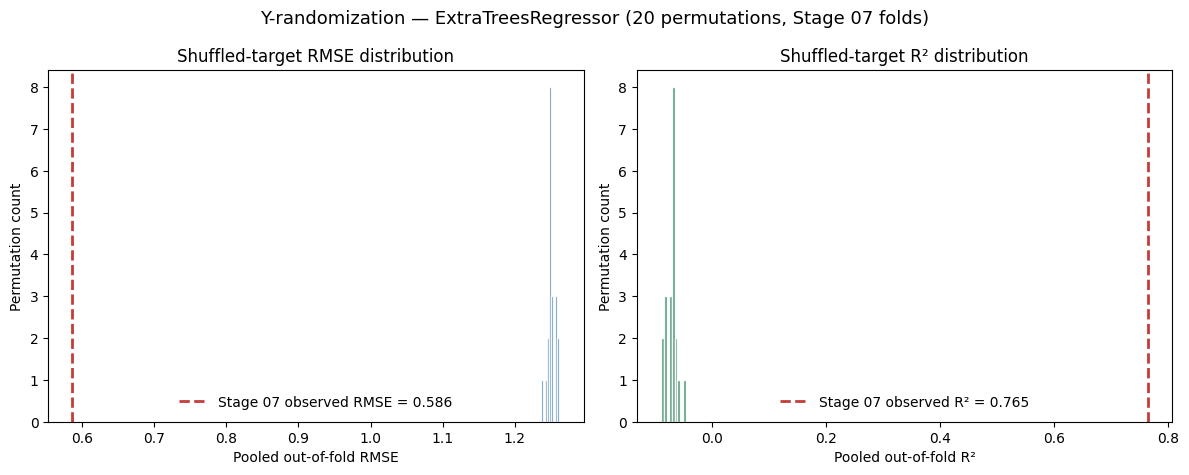


Y-RANDOMIZATION COMPLETE: ExtraTreesRegressor
Observed pooled OOF RMSE (Stage 07): 0.58650
Randomized RMSE mean ± SD          : 1.25115 ± 0.00588
Observed pooled OOF R² (Stage 07)  : 0.76484
Randomized R² mean ± SD            : -0.07021 ± 0.01006
Empirical lower-tail p (pooled RMSE): 0.04762
Minimum attainable p               : 0.04762
Results directory                  : C:\Users\USER\Documents\E\Code\outputs\16_y_randomization_stage07_folds\ExtraTreesRegressor\31f1863e8c9ede4b


,ExtraTreesRegressor
model,ExtraTreesRegressor
fingerprint,31f1863e8c9ede4b
n_randomizations,20
n_folds,5
n_training_molecules,5134
n_scaffold_groups,2120
real_pooled_oof_rmse,0.586496
real_pooled_oof_r2,0.764836
real_pooled_oof_mae,0.421421
real_mean_fold_rmse,0.589988


,model,iteration,permutation_seed,pooled_oof_rmse,pooled_oof_r2,mean_fold_rmse
0,ExtraTreesRegressor,1,9044,1.249481,-0.067332,1.250983
1,ExtraTreesRegressor,2,9045,1.246442,-0.062147,1.247943
2,ExtraTreesRegressor,3,9046,1.249322,-0.067061,1.248338
3,ExtraTreesRegressor,4,9047,1.249574,-0.067491,1.246607
4,ExtraTreesRegressor,5,9048,1.256559,-0.079459,1.256524


In [4]:
extratrees_summary, extratrees_permutations = run_model(
    "ExtraTreesRegressor",
    n_randomizations=N_RANDOMIZATIONS,
    verify_observed=VERIFY_OBSERVED,
)

display(pd.DataFrame([extratrees_summary]).T.rename(columns={0: "ExtraTreesRegressor"}))
display(extratrees_permutations.head())


## 5. Run CatBoostRegressor

Run this cell only after the ExtraTrees cell has completed. It loads the CatBoost Optuna parameters and observed metrics from Stage 07.

[CatBoostRegressor] Observed-label baseline read from Stage 07 (trial #10, brd4_f081bd1fe370_CatBoostRegressor) | pooled OOF RMSE=0.59661 | R²=0.75665
[CatBoostRegressor] Folds: cache: C:\Users\USER\Documents\E\Code\outputs\07_optuna_tuning\models\fold_feature_cache\prepared_folds_f081bd1fe370.joblib


CatBoostRegressor Y-randomization:   0%|          | 0/20 [00:00<?, ?perm/s]

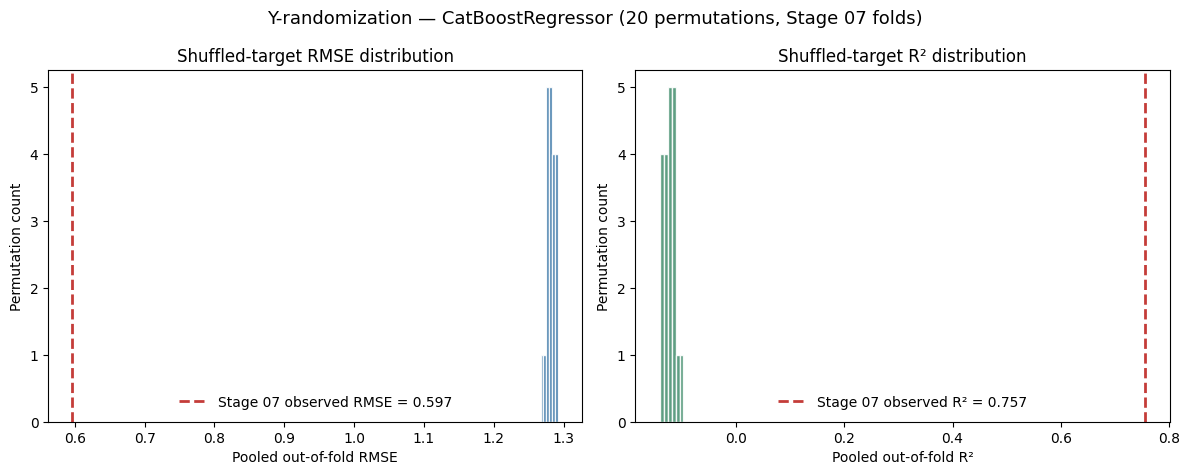


Y-RANDOMIZATION COMPLETE: CatBoostRegressor
Observed pooled OOF RMSE (Stage 07): 0.59661
Randomized RMSE mean ± SD          : 1.28170 ± 0.00654
Observed pooled OOF R² (Stage 07)  : 0.75665
Randomized R² mean ± SD            : -0.12312 ± 0.01145
Empirical lower-tail p (pooled RMSE): 0.04762
Minimum attainable p               : 0.04762
Results directory                  : C:\Users\USER\Documents\E\Code\outputs\16_y_randomization_stage07_folds\CatBoostRegressor\b03b404165bee1bb


,CatBoostRegressor
model,CatBoostRegressor
fingerprint,b03b404165bee1bb
n_randomizations,20
n_folds,5
n_training_molecules,5134
n_scaffold_groups,2120
real_pooled_oof_rmse,0.596613
real_pooled_oof_r2,0.756653
real_pooled_oof_mae,0.433822
real_mean_fold_rmse,0.59991


,model,iteration,permutation_seed,pooled_oof_rmse,pooled_oof_r2,mean_fold_rmse
0,CatBoostRegressor,1,9044,1.283680,-0.126559,1.284444
1,CatBoostRegressor,2,9045,1.271828,-0.105852,1.272979
2,CatBoostRegressor,3,9046,1.280756,-0.121432,1.278860
3,CatBoostRegressor,4,9047,1.286063,-0.130745,1.282709
4,CatBoostRegressor,5,9048,1.286898,-0.132214,1.286457


In [5]:
catboost_summary, catboost_permutations = run_model(
    "CatBoostRegressor",
    n_randomizations=N_RANDOMIZATIONS,
    verify_observed=VERIFY_OBSERVED,
)

display(pd.DataFrame([catboost_summary]).T.rename(columns={0: "CatBoostRegressor"}))
display(catboost_permutations.head())

## 6. Run SVR

Run this cell only after CatBoost has completed. SVR uses its saved Stage 07 Optuna parameters (inside the StandardScaler pipeline); it is not initialized with scikit-learn defaults.

[SVR] Observed-label baseline read from Stage 07 (trial #22, brd4_f081bd1fe370_SVR) | pooled OOF RMSE=0.58523 | R²=0.76585
[SVR] Folds: cache: C:\Users\USER\Documents\E\Code\outputs\07_optuna_tuning\models\fold_feature_cache\prepared_folds_f081bd1fe370.joblib


SVR Y-randomization:   0%|          | 0/20 [00:00<?, ?perm/s]

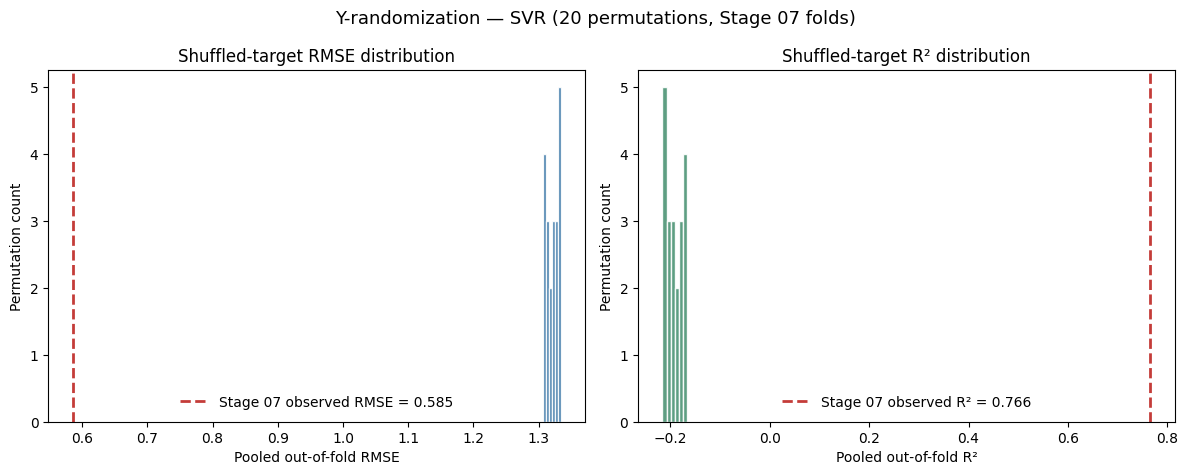


Y-RANDOMIZATION COMPLETE: SVR
Observed pooled OOF RMSE (Stage 07): 0.58523
Randomized RMSE mean ± SD          : 1.32045 ± 0.00880
Observed pooled OOF R² (Stage 07)  : 0.76585
Randomized R² mean ± SD            : -0.19206 ± 0.01588
Empirical lower-tail p (pooled RMSE): 0.04762
Minimum attainable p               : 0.04762
Results directory                  : C:\Users\USER\Documents\E\Code\outputs\16_y_randomization_stage07_folds\SVR\8b5e98d4d5c11f9c


,SVR
model,SVR
fingerprint,8b5e98d4d5c11f9c
n_randomizations,20
n_folds,5
n_training_molecules,5134
n_scaffold_groups,2120
real_pooled_oof_rmse,0.585232
real_pooled_oof_r2,0.765849
real_pooled_oof_mae,0.413342
real_mean_fold_rmse,0.588636


,model,iteration,permutation_seed,pooled_oof_rmse,pooled_oof_r2,mean_fold_rmse
0,SVR,1,9044,1.306434,-0.166851,1.308605
1,SVR,2,9045,1.328114,-0.205900,1.330061
2,SVR,3,9046,1.309749,-0.172779,1.310130
3,SVR,4,9047,1.317967,-0.187544,1.314122
4,SVR,5,9048,1.329069,-0.207633,1.327172


In [6]:
svr_summary, svr_permutations = run_model(
    "SVR",
    n_randomizations=N_RANDOMIZATIONS,
    verify_observed=VERIFY_OBSERVED,
)

display(pd.DataFrame([svr_summary]).T.rename(columns={0: "SVR"}))
display(svr_permutations.head())

## 7. Combine and compare the three completed models

In [7]:
combined_summary = combine_completed_summaries()

display(
    combined_summary[
        [
            "model",
            "n_randomizations",
            "real_pooled_oof_rmse",
            "randomized_mean_rmse",
            "randomized_sd_rmse",
            "real_pooled_oof_r2",
            "randomized_mean_r2",
            "randomized_sd_r2",
            "empirical_p_value_lower_rmse",
            "minimum_attainable_p_value",
        ]
    ].round(5)
)

Saved combined three-model summary: C:\Users\USER\Documents\E\Code\outputs\16_y_randomization_stage07_folds\combined\three_model_y_randomization_summary.csv


,model,n_randomizations,real_pooled_oof_rmse,randomized_mean_rmse,randomized_sd_rmse,real_pooled_oof_r2,randomized_mean_r2,randomized_sd_r2,empirical_p_value_lower_rmse,minimum_attainable_p_value
0,ExtraTreesRegressor,20,0.58650,1.25115,0.00588,0.76484,-0.07021,0.01006,0.04762,0.04762
1,CatBoostRegressor,20,0.59661,1.28170,0.00654,0.75665,-0.12312,0.01145,0.04762,0.04762
2,SVR,20,0.58523,1.32045,0.00880,0.76585,-0.19206,0.01588,0.04762,0.04762


Saved to: C:\Users\USER\Documents\E\Code\outputs\16_y_randomization_stage07_folds\combined\figures


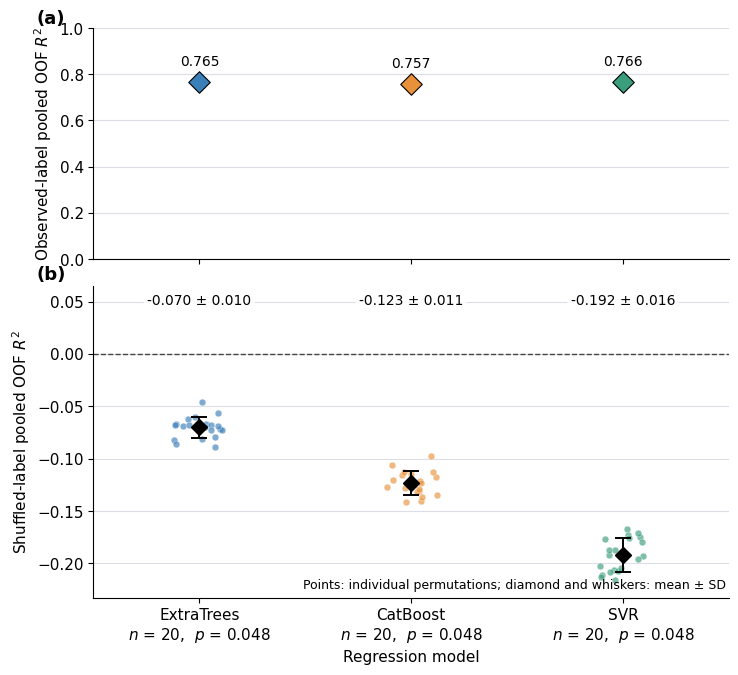

In [8]:
# Y-randomization summary figure: observed vs shuffled-label pooled OOF R²
# Panel (a): observed-label R² from Stage 07 (read, not recomputed).
# Panel (b): R² of every shuffled-target run (points) with mean ± SD (diamond + whiskers).
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

COLORS = {
    "ExtraTreesRegressor": "#3B7FB8",
    "CatBoostRegressor":   "#E8913A",
    "SVR":                 "#3A9D7C",
}
DISPLAY = {"ExtraTreesRegressor": "ExtraTrees", "CatBoostRegressor": "CatBoost", "SVR": "SVR"}
SHOW_P_VALUE = True          # add n and empirical p under each model name in panel (b)
SAVE_FIGURE = True

# ---- 1. Gather results (in-memory if the model cells ran, otherwise latest saved run) ----
def _load_run(model, mem_summary, mem_perm):
    if mem_summary is not None and mem_perm is not None:
        return mem_summary, mem_perm
    runs = sorted((OUTPUT_ROOT / model).glob("*/run_summary.json"),
                  key=lambda p: p.stat().st_mtime, reverse=True)
    if not runs:
        raise FileNotFoundError(f"No completed run for {model}. Run its notebook cell first.")
    import json
    summary = json.loads(runs[0].read_text(encoding="utf-8"))
    perm = pd.read_csv(runs[0].parent / "tables" / f"{model}_permutation_metrics.csv")
    return summary, perm

_mem = {
    "ExtraTreesRegressor": (globals().get("extratrees_summary"), globals().get("extratrees_permutations")),
    "CatBoostRegressor":   (globals().get("catboost_summary"),   globals().get("catboost_permutations")),
    "SVR":                 (globals().get("svr_summary"),        globals().get("svr_permutations")),
}
results = {m: _load_run(m, *_mem[m]) for m in MODEL_NAMES}

obs_r2  = {m: results[m][0]["real_pooled_oof_r2"] for m in MODEL_NAMES}
null_r2 = {m: results[m][1]["pooled_oof_r2"].to_numpy(float) for m in MODEL_NAMES}
p_val   = {m: results[m][0]["empirical_p_value_lower_rmse"] for m in MODEL_NAMES}
n_perm  = {m: len(null_r2[m]) for m in MODEL_NAMES}

# ---- 2. Figure ----
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
fig, (ax_a, ax_b) = plt.subplots(
    2, 1, figsize=(8.2, 7.4), sharex=True,
    gridspec_kw={"height_ratios": [1, 1.35], "hspace": 0.10},
)
x = np.arange(len(MODEL_NAMES))
rng = np.random.default_rng(0)           # fixed jitter so the figure is reproducible

# (a) observed-label R²
for i, m in enumerate(MODEL_NAMES):
    ax_a.scatter(i, obs_r2[m], marker="D", s=120, color=COLORS[m], edgecolor="black",
                 linewidth=0.8, zorder=3)
    ax_a.annotate(f"{obs_r2[m]:.3f}", (i, obs_r2[m]), xytext=(0, 12),
                  textcoords="offset points", ha="center", fontsize=10)
ax_a.set_ylim(0, 1.0)
ax_a.set_ylabel("Observed-label pooled OOF $R^2$")
ax_a.grid(axis="y", color="#dddde8", linewidth=0.8)
ax_a.set_axisbelow(True)
ax_a.text(-0.09, 1.02, "(a)", transform=ax_a.transAxes, fontweight="bold", fontsize=13)

# (b) shuffled-label R²
ax_b.axhline(0, color="#444444", linestyle="--", linewidth=1, zorder=1)
for i, m in enumerate(MODEL_NAMES):
    vals = null_r2[m]
    jitter = rng.uniform(-0.12, 0.12, size=len(vals))
    ax_b.scatter(i + jitter, vals, s=24, color=COLORS[m], alpha=0.65,
                 edgecolor="white", linewidth=0.4, zorder=2)
    mean, sd = vals.mean(), vals.std(ddof=1)
    ax_b.errorbar(i, mean, yerr=sd, fmt="D", color="black", markersize=8,
                  capsize=6, capthick=1.4, elinewidth=1.4, zorder=4)

all_null = np.concatenate(list(null_r2.values()))
span = max(all_null.max(), 0) - all_null.min()
ax_b.set_ylim(all_null.min() - 0.08 * span, max(all_null.max(), 0) + 0.30 * span)

# mean ± SD labels pinned to the top of the panel, so they never overlap the points
for i, m in enumerate(MODEL_NAMES):
    vals = null_r2[m]
    ax_b.text(i, 0.975, f"{vals.mean():.3f} ± {vals.std(ddof=1):.3f}",
              transform=ax_b.get_xaxis_transform(), ha="center", va="top", fontsize=10,
              bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.85))

ax_b.set_ylabel("Shuffled-label pooled OOF $R^2$")
ax_b.grid(axis="y", color="#dddde8", linewidth=0.8)
ax_b.set_axisbelow(True)
ax_b.text(-0.09, 1.02, "(b)", transform=ax_b.transAxes, fontweight="bold", fontsize=13)
ax_b.set_xlim(-0.5, len(MODEL_NAMES) - 0.5)
ax_b.set_xticks(x)
ticklabels = []
for m in MODEL_NAMES:
    label = DISPLAY[m]
    if SHOW_P_VALUE:
        label += f"\n$n$ = {n_perm[m]},  $p$ = {p_val[m]:.3f}"
    ticklabels.append(label)
ax_b.set_xticklabels(ticklabels)
ax_b.set_xlabel("Regression model")
ax_b.text(0.995, 0.02,
          "Points: individual permutations; diamond and whiskers: mean ± SD",
          transform=ax_b.transAxes, ha="right", va="bottom", fontsize=9)

# ---- 3. Save + show ----
if SAVE_FIGURE:
    out_dir = OUTPUT_ROOT / "combined" / "figures"
    out_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_dir / "y_randomization_observed_vs_shuffled_r2.png", dpi=400, bbox_inches="tight")
    fig.savefig(out_dir / "y_randomization_observed_vs_shuffled_r2.pdf", bbox_inches="tight")
    print("Saved to:", out_dir)
plt.show()